## Hourly data

Evaluate different models on the test set (December) and compare performance across quantiles of the significant wave height. Plot selected case studies as well as summary statistics.

In [ ]:
import xarray as xr
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.metrics import root_mean_squared_error

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
sns.set_style("whitegrid")

In [ ]:
ds_true = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr")
ds_true = ds_true.isel(time=slice(334*24, 364*24))
ds_true["prev_sigWaveHeight"] = ds_true["sigWaveHeight"].shift({"time": 1})
ds_true["delta_sigWaveHeight"] = ds_true["sigWaveHeight"].diff("time")
# need to remove the first entry
ds_true = ds_true.isel(time=slice(1, None))

In [ ]:
tmax = ds_true["delta_sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").argmax().compute().item()
tmin = ds_true["delta_sigWaveHeight"].isel(time=slice(10, -10)).std(dim="nSCHISM_hgrid_node").argmin().compute().item()

In [ ]:
experiments = {}
experiments["densenet"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2026-05-12_12-28-55/predictions.nc"}
experiments["lstm-3"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_lstm/runs/2026-05-13_13-08-03/predictions.nc"}
experiments["lstm-48"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_lstm/runs/2026-05-13_13-53-09/predictions.nc"}
experiments["gcn-epd"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_gcn_epd/runs/2026-05-12_09-47-51/predictions.nc"}
experiments["gat-preliminary"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_gat_epd/runs/2026-05-12_09-54-20/predictions.nc"}
experiments["gcn-lstm-3"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_gcn_lstm/runs/2026-04-15_16-25-04/predictions.nc"}
experiments["gat-center-lstm-3"] = {"predictions": ""}
experiments["gcn-center-lstm-3"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_gcn_lstm_center_vn/runs/2026-04-24_09-25-46/predictions.nc"}
experiments["gcn-center-lstm-48"] = {"predictions": "/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_gcn_lstm_center_vn/runs/2026-05-08_13-28-17/predictions.nc"}

In [ ]:
expkeys = list(experiments.keys())

## Setup

In [ ]:
all_ds = []
for key, val in experiments.items():
    if val["predictions"] is not None:
        all_ds.append(xr.open_dataset(val["predictions"]))

In [ ]:
all_ds = xr.concat(all_ds, dim="experiment", join="inner")

In [ ]:
ds_true = ds_true.sel(time=all_ds.time)

In [ ]:
for a, b, c in zip(expkeys, all_ds["sigWaveHeight"].min(dim=("time", "nSCHISM_hgrid_node")).compute().values, all_ds["sigWaveHeight"].max(dim=("time", "nSCHISM_hgrid_node")).compute().values):
    print(f"{a:20s}: swh_min = {b:+.2f} m / swh_max = {c:+.2f} m")

densenet            : swh_min = +0.00 m / swh_max = +6.61 m
lstm-3              : swh_min = +0.00 m / swh_max = +7.03 m
lstm-48             : swh_min = +0.00 m / swh_max = +7.02 m
gcn-epd             : swh_min = -0.05 m / swh_max = +7.01 m
gat-preliminary     : swh_min = +0.00 m / swh_max = +7.01 m
gcn-lstm-3          : swh_min = -0.26 m / swh_max = +6.96 m
gcn-center-lstm-3   : swh_min = -0.82 m / swh_max = +7.04 m
gcn-center-lstm-48  : swh_min = +0.00 m / swh_max = +7.13 m


## RMSE for all runs

In [ ]:
all_rmse = {}

for i, exp in enumerate(expkeys):
    all_rmse[exp] = root_mean_squared_error(all_ds.isel(experiment=i)["sigWaveHeight"].values, ds_true["sigWaveHeight"].values)

In [ ]:
tmpdf = pd.DataFrame(all_rmse, index=[0]).melt(var_name="experiment", value_name="rmse")

In [ ]:
persistence_rmse = root_mean_squared_error(ds_true["prev_sigWaveHeight"].values, ds_true["sigWaveHeight"].values)

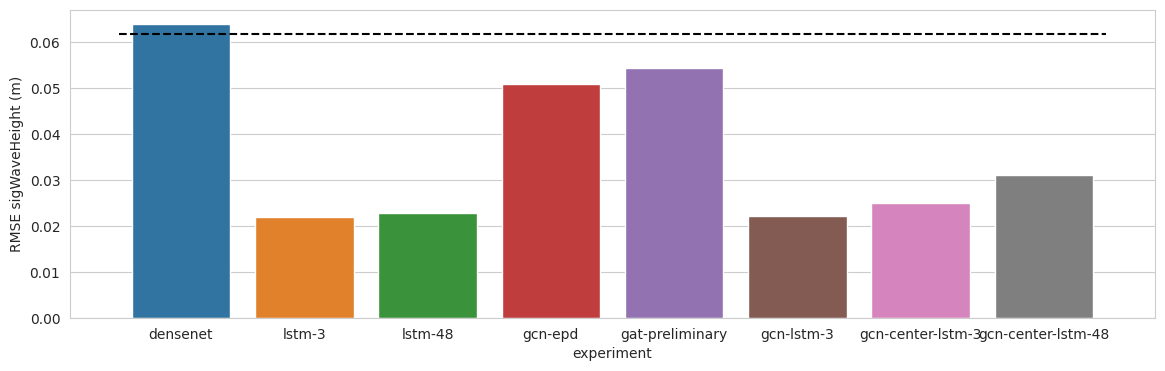

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 4))
sns.barplot(tmpdf, x="experiment", y="rmse", hue="experiment")
ax.set_ylabel("RMSE sigWaveHeight (m)")
x1, x2 = ax.get_xlim()
ax.hlines(persistence_rmse, x1, x2, ls="--", color="k")
plt.show()

## Performance on selected quantiles

### Significant wave height

In [ ]:
quantiles = [0, 0.5, 0.9, 0.99, 0.999]
swh_quantiles = np.quantile(ds_true["sigWaveHeight"], quantiles)

In [ ]:
swh_quantiles

array([0.        , 1.14632201, 1.95913482, 3.87433672, 4.11870623])

In [ ]:
swh_bins = [0.5, 1, 2, 3, 4, 100]
swh_labels = ["0 - 0.5", "0.5 - 1", "1 - 2", "2 - 3", "3 - 4", "> 4"]
swh_digitize = np.digitize(ds_true["sigWaveHeight"], swh_bins)

In [ ]:
all_rmse = {}

for i, exp in enumerate(expkeys):
    this_rmse = []
    for j in range(len(swh_bins)):
        cond = swh_digitize == j
        if i == 0:
            print(j, swh_labels[j], np.sum(cond))
        this_rmse.append(root_mean_squared_error(all_ds.isel(experiment=i)["sigWaveHeight"].values[cond], ds_true["sigWaveHeight"].values[cond]))
        
    all_rmse[exp] = this_rmse

0 0 - 0.5 52559981
1 0.5 - 1 115024076
2 1 - 2 192659584
3 2 - 3 22307946
4 3 - 4 12002069
5 > 4 1541960


In [ ]:
tmpdf = pd.DataFrame(all_rmse, index=list(range(len(swh_bins)))).melt(var_name="experiment")
tmpdf["swh"] = swh_bins * len(expkeys)

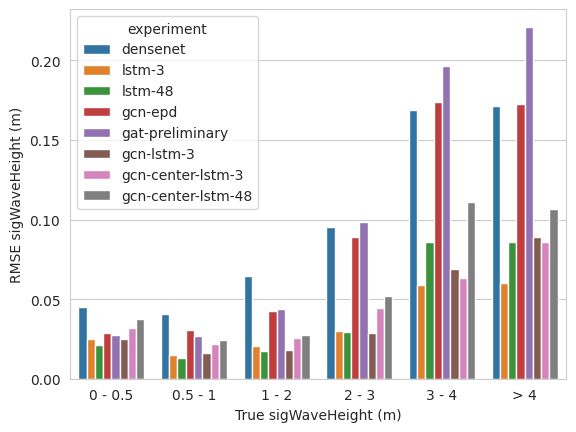

In [ ]:
fig, ax = plt.subplots(1, 1)
sns.barplot(tmpdf, x="swh", y="value", hue="experiment")
ax.set_ylabel("RMSE sigWaveHeight (m)")
#x1, x2 = ax.get_xlim()
#ax.hlines(persistence_rmse, x1, x2, ls="--", color="k")
ax.set_xticks(list(range(len(swh_labels))))
ax.set_xticklabels(swh_labels)
ax.set_xlabel("True sigWaveHeight (m)")
plt.show()

### Change in significant wave height

In [ ]:
quantiles = [0, 0.5, 0.9, 0.99, 0.999]
swh_quantiles = np.quantile(ds_true["delta_sigWaveHeight"], quantiles)

In [ ]:
ds_true["delta_sigWaveHeight"].max().values

array(1.8742071, dtype=float32)

In [ ]:
dswh_bins = [-1, -0.5, 0, 0.5, 1, 3]
dswh_labels = ["- 1-2", "- 0.5-1", "- 0-0.5", "0-0.5", "0.5-1", "1-2",] 
dswh_digitize = np.digitize(ds_true["delta_sigWaveHeight"], dswh_bins)

In [ ]:
all_rmse = {}

for i, exp in enumerate(expkeys):
    this_rmse = []
    for j in range(len(dswh_bins)):
        cond = dswh_digitize == j
        if i == 0:
            print(j, dswh_labels[j], np.sum(cond))
        this_rmse.append(root_mean_squared_error(all_ds.isel(experiment=i)["sigWaveHeight"].values[cond], ds_true["sigWaveHeight"].values[cond]))
        
    all_rmse[exp] = this_rmse

0 - 1-2 3267
1 - 0.5-1 35225
2 - 0-0.5 220610504
3 0-0.5 175430590
4 0.5-1 13246
5 1-2 2784


In [ ]:
tmpdf = pd.DataFrame(all_rmse, index=list(range(len(dswh_bins)))).melt(var_name="experiment")
tmpdf["dswh"] = dswh_bins * len(expkeys)

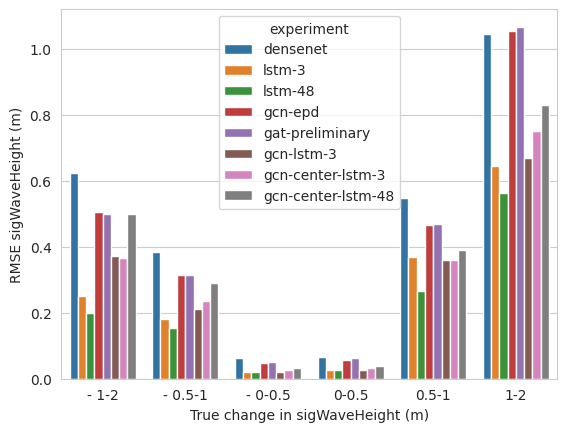

In [ ]:
fig, ax = plt.subplots(1, 1)
sns.barplot(tmpdf, x="dswh", y="value", hue="experiment")
ax.set_ylabel("RMSE sigWaveHeight (m)")
#x1, x2 = ax.get_xlim()
#ax.hlines(persistence_rmse, x1, x2, ls="--", color="k")
ax.set_xticks(list(range(len(dswh_labels))))
ax.set_xticklabels(dswh_labels)
ax.set_xlabel("True change in sigWaveHeight (m)")
plt.show()

## Bias for different bins of delta_sigWaveHeight

In [ ]:
all_bias = {}

for i, exp in enumerate(expkeys):
    this_bias = {}
    for j in range(len(dswh_bins)):
        cond = dswh_digitize == j
        if i == 0:
            print(j, dswh_labels[j], np.sum(cond))
        this_bias[f"{j}"] = np.random.choice(all_ds.isel(experiment=i)["sigWaveHeight"].values[cond] - ds_true["sigWaveHeight"].values[cond], size=100, replace=False)
        
    all_bias[exp] = this_bias

0 - 1-2 3267
1 - 0.5-1 35225
2 - 0-0.5 220610504
3 0-0.5 175430590
4 0.5-1 13246
5 1-2 2784


In [ ]:
tmpdf = pd.DataFrame(all_bias).melt(var_name="experiment")
tmpdf["dswh"] = dswh_bins * len(expkeys)

In [ ]:
tmpdf

,experiment,value,dswh
0,densenet,"[0.6220124, 0.5567765, 0.52631474, 0.5986881, ...",-1.0
1,densenet,"[0.06769657, 0.12118626, 0.12848377, 0.3293199...",-0.5
2,densenet,"[0.03244877, -0.047420084, 0.014503241, -0.001...",0.0
3,densenet,"[0.030529141, 0.006033182, 0.17934608, -0.0090...",0.5
4,densenet,"[-0.27762747, -0.56537056, -0.48905742, -0.631...",1.0
5,densenet,"[-0.9691458, -0.8848527, -0.9768598, -0.901088...",3.0
6,lstm-3,"[0.20901299, 0.17222404, 0.29523993, 0.2796387...",-1.0
7,lstm-3,"[0.067436695, 0.13096523, 0.019588709, 0.07499...",-0.5
8,lstm-3,"[-0.083592415, 0.03079927, 0.015277505, -0.004...",0.0
9,lstm-3,"[-0.01803124, 0.015954494, 0.04820931, -0.0078...",0.5


Text(0.5, 0, 'True change in sigWaveHeight (m)')

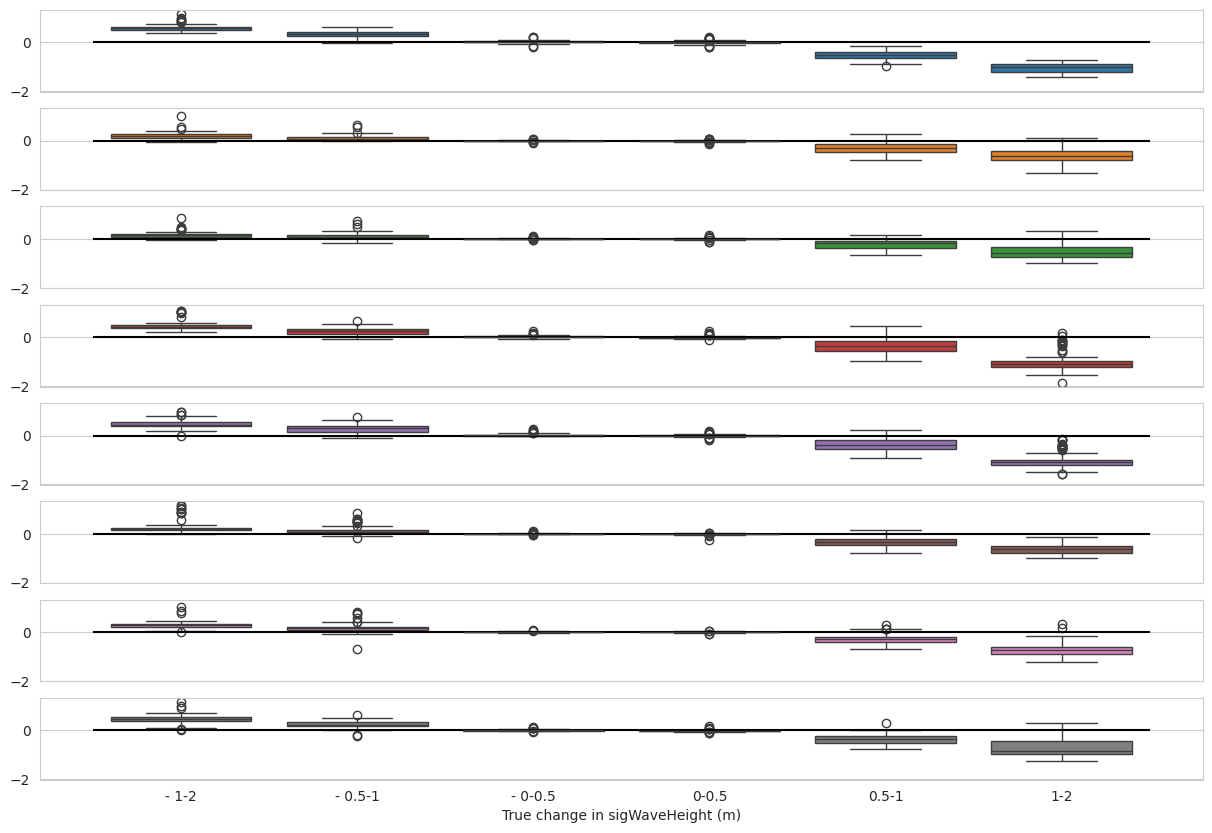

In [ ]:
fig, ax = plt.subplots(len(expkeys), 1, sharex=True, sharey=True, figsize=(15, 10))

for i, exp in enumerate(expkeys):
    sns.boxplot(all_bias[exp], ax=ax[i], color=f"C{i}")
    ax[i].hlines(0, -0.5, 5.5, color="k")

ax[-1].set_xticks(list(range(len(dswh_labels))))
ax[-1].set_xticklabels(dswh_labels)
ax[-1].set_xlabel("True change in sigWaveHeight (m)")

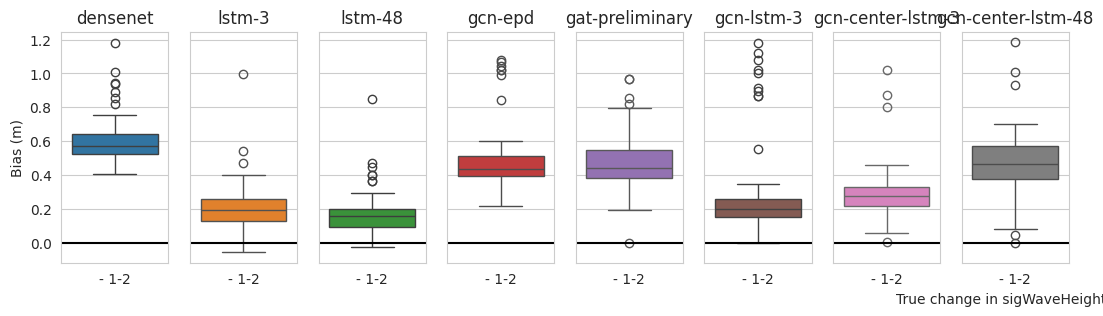

In [ ]:
fig, ax = plt.subplots(1, len(expkeys), sharex=True, sharey=True, figsize=(13, 3))

for i, exp in enumerate(expkeys):
    sns.boxplot(all_bias[exp]["0"], ax=ax[i], color=f"C{i}")
    ax[i].set_title(exp)
    ax[i].hlines(0, -0.5, 0.5, color="k")

ax[-1].set_xticks(list(range(len(dswh_labels))))
ax[-1].set_xticklabels(dswh_labels)
ax[-1].set_xlabel("True change in sigWaveHeight (m)")
ax[-1].set_xlim(-0.5, 0.5)
ax[0].set_ylabel("Bias (m)")
plt.show()

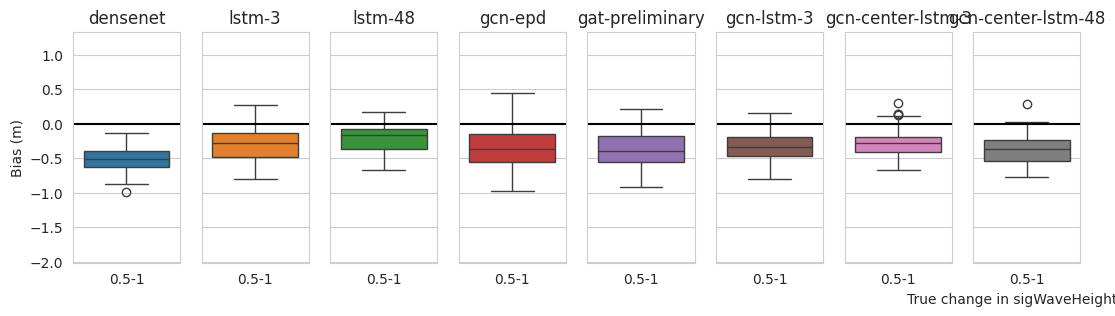

In [ ]:
fig, ax = plt.subplots(1, len(expkeys), sharex=True, sharey=True, figsize=(13, 3))

for i, exp in enumerate(expkeys):
    sns.boxplot(all_bias[exp], ax=ax[i], color=f"C{i}")
    ax[i].set_title(exp)
    ax[i].hlines(0, 3.5, 4.5, "k")

ax[-1].set_xticks(list(range(len(dswh_labels))))
ax[-1].set_xticklabels(dswh_labels)
ax[-1].set_xlabel("True change in sigWaveHeight (m)")
ax[-1].set_xlim(3.5, 4.5)
ax[0].set_ylabel("Bias (m)")
plt.show()

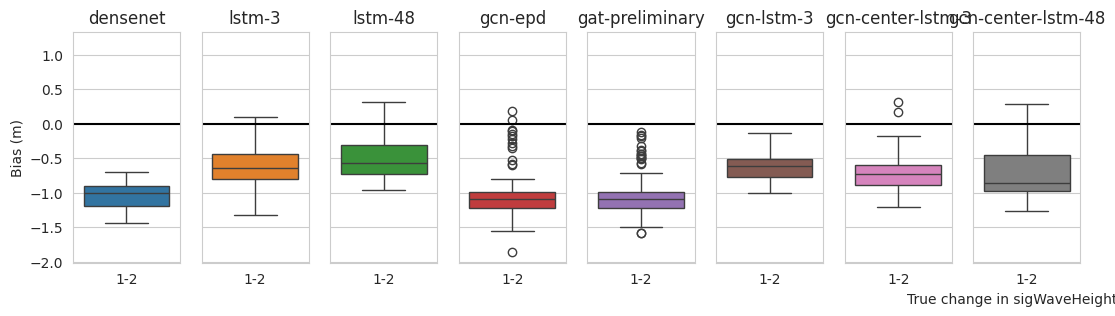

In [ ]:
fig, ax = plt.subplots(1, len(expkeys), sharex=True, sharey=True, figsize=(13, 3))

for i, exp in enumerate(expkeys):
    sns.boxplot(all_bias[exp], ax=ax[i], color=f"C{i}")
    ax[i].set_title(exp)
    ax[i].hlines(0, 4.5, 5.5, "k")

ax[-1].set_xticks(list(range(len(dswh_labels))))
ax[-1].set_xticklabels(dswh_labels)
ax[-1].set_xlabel("True change in sigWaveHeight (m)")
ax[-1].set_xlim(4.5, 5.5)
ax[0].set_ylabel("Bias (m)")
plt.show()

## Case studies

In [ ]:
import sys
sys.path.append("..")

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from src.utils.plot_utils import regrid_to_regular, plot_on_map, plot_bias_on_map

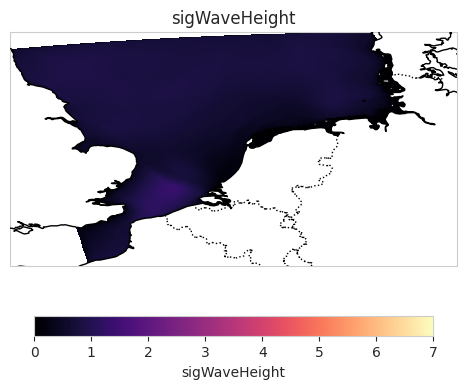

In [ ]:
tmp = regrid_to_regular(ds_true["sigWaveHeight"].isel(time=653), 1000, x_coord="SCHISM_hgrid_node_x", y_coord="SCHISM_hgrid_node_y")
_=plot_on_map(tmp, vmin=0, vmax=7, cmap="magma", figsize=(6, 4))

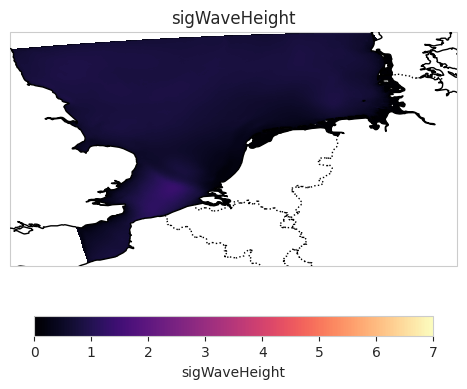

In [ ]:
tmp = regrid_to_regular(all_ds.isel(experiment=5)["sigWaveHeight"].isel(time=653), 1000, x_coord="SCHISM_hgrid_node_x", y_coord="SCHISM_hgrid_node_y")
_=plot_on_map(tmp, vmin=0, vmax=7, cmap="magma", figsize=(6, 4))

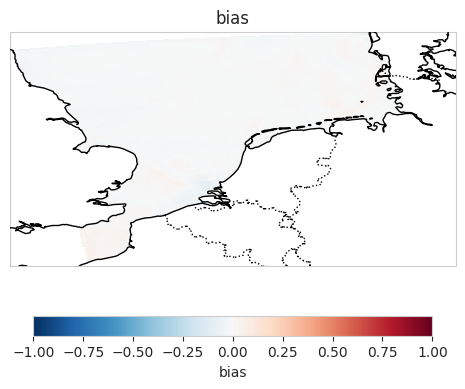

In [ ]:
_ = plot_bias_on_map(all_ds.isel(experiment=5)["sigWaveHeight"].isel(time=653), ds_true["sigWaveHeight"].isel(time=653), vlim=1, resolution=5000, figsize=(6, 4))